<a href="https://colab.research.google.com/github/helenajemima/Kel1-Tugas-P6-Machine-Learning-2026-2027/blob/main/Heart_Disease_Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    silhouette_score
)

from sklearn.decomposition import PCA

import warnings
warnings.filterwarnings("ignore")

# Pengaturan tampilan
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 150)

print("Library berhasil diimpor.")
print("Scikit-learn version:", sklearn.__version__)


Library berhasil diimpor.
Scikit-learn version: 1.6.1


In [2]:
CSV_URL = "https://raw.githubusercontent.com/helenajemima/Kel1-Tugas-P6-Machine-Learning-2026-2027/refs/heads/main/heart_modified.csv"

df = pd.read_csv(CSV_URL)

print("Dataset berhasil dimuat.")
print("Ukuran dataset:", df.shape)

display(df.head())


Dataset berhasil dimuat.
Ukuran dataset: (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140.0,289.0,0,Normal,172.0,N,0.0,Up,0
1,49,F,NAP,160.0,NaN,0,Normal,156.0,N,1.0,Flat,1
2,37,M,ATA,130.0,283.0,0,ST,98.0,N,0.0,Up,0
3,48,F,ASY,138.0,214.0,0,Normal,108.0,Y,1.5,Flat,1
4,54,M,NAP,150.0,195.0,0,Normal,122.0,N,0.0,Up,0


In [3]:
print("Informasi Dataset:")
df.info()

print("\nJumlah baris dan kolom:")
print(df.shape)

print("\nNama kolom:")
print(df.columns.tolist())

print("\nLima data pertama:")
display(df.head())

print("\nStatistik deskriptif sebelum preprocessing:")
display(df.describe(include="all").T)

print("\nJumlah missing values sebelum preprocessing:")
display(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())


Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       900 non-null    float64
 4   Cholesterol     900 non-null    float64
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           900 non-null    float64
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(4), int64(3), object(5)
memory usage: 86.2+ KB

Jumlah baris dan kolom:
(918, 12)

Nama kolom:
['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope'

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140.0,289.0,0,Normal,172.0,N,0.0,Up,0
1,49,F,NAP,160.0,NaN,0,Normal,156.0,N,1.0,Flat,1
2,37,M,ATA,130.0,283.0,0,ST,98.0,N,0.0,Up,0
3,48,F,ASY,138.0,214.0,0,Normal,108.0,Y,1.5,Flat,1
4,54,M,NAP,150.0,195.0,0,Normal,122.0,N,0.0,Up,0



Statistik deskriptif sebelum preprocessing:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,918.0,NaN,NaN,NaN,53.510893,9.432617,28.0,47.0,54.0,60.0,77.0
Sex,918,2,M,725,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ChestPainType,918,4,ASY,496,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RestingBP,900.0,NaN,NaN,NaN,132.411111,18.611534,0.0,120.0,130.0,140.0,200.0
Cholesterol,900.0,NaN,NaN,NaN,199.252222,109.644221,0.0,173.75,223.0,267.25,603.0
FastingBS,918.0,NaN,NaN,NaN,0.233115,0.423046,0.0,0.0,0.0,0.0,1.0
RestingECG,918,3,Normal,552,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MaxHR,900.0,NaN,NaN,NaN,136.874444,25.557038,60.0,120.0,138.0,156.0,202.0
ExerciseAngina,918,2,N,547,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Oldpeak,918.0,NaN,NaN,NaN,0.887364,1.06657,-2.6,0.0,0.6,1.5,6.2



Jumlah missing values sebelum preprocessing:


,0
Age,0
Sex,0
ChestPainType,0
RestingBP,18
Cholesterol,18
FastingBS,0
RestingECG,0
MaxHR,18
ExerciseAngina,0
Oldpeak,0



Total missing values:
54


In [4]:
target_column = "HeartDisease"

assert target_column in df.columns, "Kolom HeartDisease tidak ditemukan!"

X = df.drop(columns=[target_column])
y = df[target_column]

numeric_features = [
    "Age",
    "RestingBP",
    "Cholesterol",
    "MaxHR",
    "Oldpeak"
]

categorical_features = [
    "Sex",
    "ChestPainType",
    "FastingBS",
    "RestingECG",
    "ExerciseAngina",
    "ST_Slope"
]

assert set(numeric_features + categorical_features) == set(X.columns), \
    "Daftar atribut numerik dan kategorik tidak sesuai dengan kolom dataset!"

print("Atribut prediktor:", len(X.columns))
print("Atribut numerik:", len(numeric_features))
print("Atribut kategorik:", len(categorical_features))
print("Atribut label:", target_column)

print("\nAtribut numerik:")
print(numeric_features)

print("\nAtribut kategorik:")
print(categorical_features)


Atribut prediktor: 11
Atribut numerik: 5
Atribut kategorik: 6
Atribut label: HeartDisease

Atribut numerik:
['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']

Atribut kategorik:
['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina', 'ST_Slope']


In [6]:
numeric_features = [
    "Age",
    "RestingBP",
    "Cholesterol",
    "MaxHR",
    "Oldpeak"
]

categorical_features = [
    "Sex",
    "ChestPainType",
    "FastingBS",
    "RestingECG",
    "ExerciseAngina",
    "ST_Slope"
]

target_column = "HeartDisease"

attribute_info = []

for column in df.columns:

    unique_values = df[column].dropna().unique()

    if column == target_column:
        role = "Label"
        attribute_type = "Kategorik Biner"
    else:
        role = "Prediktor"

        if column in numeric_features:
            attribute_type = "Numerik"
        elif column in categorical_features:
            if df[column].nunique() == 2:
                attribute_type = "Kategorik Biner"
            else:
                attribute_type = "Kategorik"
        else:
            attribute_type = "Belum diklasifikasikan"

    if column in categorical_features or column == target_column:
        unique_display = sorted(unique_values.tolist(), key=str)
    else:
        unique_display = "-"

    attribute_info.append({
        "Nama Atribut": column,
        "Peran Atribut": role,
        "Jenis Atribut": attribute_type,
        "Jumlah Nilai Unik": df[column].nunique(),
        "Nilai Unik (Kategorik)": unique_display
    })

attribute_info_df = pd.DataFrame(attribute_info)

print("TABEL IDENTIFIKASI ATRIBUT DATASET")
display(attribute_info_df)


TABEL IDENTIFIKASI ATRIBUT DATASET


,Nama Atribut,Peran Atribut,Jenis Atribut,Jumlah Nilai Unik,Nilai Unik (Kategorik)
0,Age,Prediktor,Numerik,50,-
1,Sex,Prediktor,Kategorik Biner,2,"[F, M]"
2,ChestPainType,Prediktor,Kategorik,4,"[ASY, ATA, NAP, TA]"
3,RestingBP,Prediktor,Numerik,67,-
4,Cholesterol,Prediktor,Numerik,219,-
5,FastingBS,Prediktor,Kategorik Biner,2,"[0, 1]"
6,RestingECG,Prediktor,Kategorik,3,"[LVH, Normal, ST]"
7,MaxHR,Prediktor,Numerik,119,-
8,ExerciseAngina,Prediktor,Kategorik Biner,2,"[N, Y]"
9,Oldpeak,Prediktor,Numerik,53,-


In [7]:
df_clean = df.copy()

zero_columns = ["RestingBP", "Cholesterol"]

print("Pemeriksaan nilai nol:")

for column in zero_columns:

    zero_count = (df_clean[column] == 0).sum()

    print(f"{column}: {zero_count} nilai nol")

    df_clean[column] = df_clean[column].replace(0, np.nan)

print("\nMissing values setelah pemeriksaan nilai nol:")
display(df_clean.isnull().sum())

print("\nTotal missing values setelah pemeriksaan tambahan:")
print(df_clean.isnull().sum().sum())


Pemeriksaan nilai nol:
RestingBP: 1 nilai nol
Cholesterol: 169 nilai nol

Missing values setelah pemeriksaan nilai nol:


,0
Age,0
Sex,0
ChestPainType,0
RestingBP,19
Cholesterol,187
FastingBS,0
RestingECG,0
MaxHR,18
ExerciseAngina,0
Oldpeak,0



Total missing values setelah pemeriksaan tambahan:
224


In [8]:
print("Distribusi HeartDisease:")
display(df_clean["HeartDisease"].value_counts().sort_index())

print("\nDistribusi dalam persentase:")
display(
    df_clean["HeartDisease"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)


Distribusi HeartDisease:


,count
HeartDisease,
0,410
1,508



Distribusi dalam persentase:


,proportion
HeartDisease,
0,44.66
1,55.34


In [9]:
try:
    onehot_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )

except TypeError:
    onehot_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )


# Pipeline atribut numerik
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler())
])


# Pipeline atribut kategorik
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", onehot_encoder)
])


def create_preprocessor():

    return ColumnTransformer(
        transformers=[
            ("num", numeric_transformer, numeric_features),
            ("cat", categorical_transformer, categorical_features)
        ],
        remainder="drop"
    )


print("Preprocessing pipeline berhasil dibuat.")


Preprocessing pipeline berhasil dibuat.


In [10]:
X = df_clean.drop(columns=["HeartDisease"])
y = df_clean["HeartDisease"]

cluster_preprocessor = create_preprocessor()

X_cluster_array = cluster_preprocessor.fit_transform(X)

feature_names = cluster_preprocessor.get_feature_names_out()

X_cluster = pd.DataFrame(
    X_cluster_array,
    columns=feature_names,
    index=X.index
)

print("Preprocessing clustering selesai.")
print("Ukuran data sebelum preprocessing:", X.shape)
print("Ukuran data setelah preprocessing:", X_cluster.shape)

display(X_cluster.head())


Preprocessing clustering selesai.
Ukuran data sebelum preprocessing: (918, 11)
Ukuran data setelah preprocessing: (918, 21)


,num__Age,num__RestingBP,num__Cholesterol,num__MaxHR,num__Oldpeak,cat__Sex_F,cat__Sex_M,cat__ChestPainType_ASY,cat__ChestPainType_ATA,cat__ChestPainType_NAP,cat__ChestPainType_TA,cat__FastingBS_0,cat__FastingBS_1,cat__RestingECG_LVH,cat__RestingECG_Normal,cat__RestingECG_ST,cat__ExerciseAngina_N,cat__ExerciseAngina_Y,cat__ST_Slope_Down,cat__ST_Slope_Flat,cat__ST_Slope_Up
0,-1.433140,0.415933,8.293202e-01,1.388846,-0.832432,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
1,-0.478484,1.533793,5.395897e-16,0.756215,0.105664,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
2,-1.751359,-0.142996,7.154094e-01,-1.537075,-0.832432,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0
3,-0.584556,0.304147,-5.945643e-01,-1.141681,0.574711,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
4,0.051881,0.974863,-9.552817e-01,-0.588128,-0.832432,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0


In [11]:
print("Statistik deskriptif setelah preprocessing:")

display(X_cluster.describe().T)

print("\nPemeriksaan missing values setelah preprocessing:")

print(X_cluster.isnull().sum().sum())


Statistik deskriptif setelah preprocessing:


,count,mean,std,min,25%,50%,75%,max
num__Age,918.0,-1.083616e-16,1.000545,-2.706015,-0.690629,5.188098e-02,0.688318,2.491558
num__RestingBP,918.0,-5.147178e-16,1.000545,-2.937645,-0.701926,-1.429965e-01,0.415933,3.769512
num__Cholesterol,918.0,3.657205e-16,1.000545,-3.043646,-0.556594,5.395897e-16,0.406901,6.790650
num__MaxHR,918.0,-7.894919e-16,1.000545,-3.039576,-0.667207,2.473414e-02,0.716675,2.575031
num__Oldpeak,918.0,1.238419e-16,1.000545,-3.271482,-0.832432,-2.695748e-01,0.574711,4.983762
cat__Sex_F,918.0,2.102397e-01,0.407701,0.000000,0.000000,0.000000e+00,0.000000,1.000000
cat__Sex_M,918.0,7.897603e-01,0.407701,0.000000,1.000000,1.000000e+00,1.000000,1.000000
cat__ChestPainType_ASY,918.0,5.403050e-01,0.498645,0.000000,0.000000,1.000000e+00,1.000000,1.000000
cat__ChestPainType_ATA,918.0,1.884532e-01,0.391287,0.000000,0.000000,0.000000e+00,0.000000,1.000000
cat__ChestPainType_NAP,918.0,2.211329e-01,0.415236,0.000000,0.000000,0.000000e+00,0.000000,1.000000



Pemeriksaan missing values setelah preprocessing:
0


In [12]:
numeric_before = df_clean[numeric_features].describe().T

print("1. STATISTIK ATRIBUT NUMERIK SEBELUM PREPROCESSING")
display(numeric_before)

numeric_stats_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler())
])

numeric_after_array = numeric_stats_pipeline.fit_transform(
    df_clean[numeric_features]
)

numeric_after = pd.DataFrame(
    numeric_after_array,
    columns=numeric_features,
    index=df_clean.index
)

numeric_after_stats = numeric_after.describe().T

print("\n2. STATISTIK ATRIBUT NUMERIK SETELAH IMPUTASI DAN STANDARDSCALER")
display(numeric_after_stats)

categorical_encoded_columns = [
    column for column in X_cluster.columns
    if column.startswith("cat__")
]

categorical_after = X_cluster[categorical_encoded_columns]

categorical_after_stats = categorical_after.describe().T

print("\n3. STATISTIK FITUR KATEGORIK SETELAH ONE-HOT ENCODING")
display(categorical_after_stats)

print("\n4. PEMERIKSAAN MISSING VALUES SETELAH IMPUTASI")
print(
    "Jumlah missing values:",
    numeric_after.isnull().sum().sum()
)


1. STATISTIK ATRIBUT NUMERIK SEBELUM PREPROCESSING


,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.510893,9.432617,28.0,47.0,54.0,60.0,77.0
RestingBP,899.0,132.558398,18.089473,80.0,120.0,130.0,140.0,200.0
Cholesterol,731.0,245.317373,59.067205,85.0,208.0,238.0,275.5,603.0
MaxHR,900.0,136.874444,25.557038,60.0,120.0,138.0,156.0,202.0
Oldpeak,918.0,0.887364,1.066570,-2.6,0.0,0.6,1.5,6.2



2. STATISTIK ATRIBUT NUMERIK SETELAH IMPUTASI DAN STANDARDSCALER


,count,mean,std,min,25%,50%,75%,max
Age,918.0,-1.083616e-16,1.000545,-2.706015,-0.690629,5.188098e-02,0.688318,2.491558
RestingBP,918.0,-5.147178e-16,1.000545,-2.937645,-0.701926,-1.429965e-01,0.415933,3.769512
Cholesterol,918.0,3.657205e-16,1.000545,-3.043646,-0.556594,5.395897e-16,0.406901,6.790650
MaxHR,918.0,-7.894919e-16,1.000545,-3.039576,-0.667207,2.473414e-02,0.716675,2.575031
Oldpeak,918.0,1.238419e-16,1.000545,-3.271482,-0.832432,-2.695748e-01,0.574711,4.983762



3. STATISTIK FITUR KATEGORIK SETELAH ONE-HOT ENCODING


,count,mean,std,min,25%,50%,75%,max
cat__Sex_F,918.0,0.210240,0.407701,0.0,0.0,0.0,0.0,1.0
cat__Sex_M,918.0,0.789760,0.407701,0.0,1.0,1.0,1.0,1.0
cat__ChestPainType_ASY,918.0,0.540305,0.498645,0.0,0.0,1.0,1.0,1.0
cat__ChestPainType_ATA,918.0,0.188453,0.391287,0.0,0.0,0.0,0.0,1.0
cat__ChestPainType_NAP,918.0,0.221133,0.415236,0.0,0.0,0.0,0.0,1.0
cat__ChestPainType_TA,918.0,0.050109,0.218289,0.0,0.0,0.0,0.0,1.0
cat__FastingBS_0,918.0,0.766885,0.423046,0.0,1.0,1.0,1.0,1.0
cat__FastingBS_1,918.0,0.233115,0.423046,0.0,0.0,0.0,0.0,1.0
cat__RestingECG_LVH,918.0,0.204793,0.403770,0.0,0.0,0.0,0.0,1.0
cat__RestingECG_Normal,918.0,0.601307,0.489896,0.0,0.0,1.0,1.0,1.0



4. PEMERIKSAAN MISSING VALUES SETELAH IMPUTASI
Jumlah missing values: 0


In [ ]:
X_classification = df_clean.drop(columns=["HeartDisease"])
y_classification = df_clean["HeartDisease"]

X_train, X_test, y_train, y_test = train_test_split(
    X_classification,
    y_classification,
    test_size=0.15,
    random_state=42,
    stratify=y_classification
)

print("Pembagian data berhasil.")

print("\nJumlah data keseluruhan:", len(X_classification))
print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

print("\nPersentase training:",
      round(len(X_train) / len(X_classification) * 100, 2), "%")

print("Persentase testing:",
      round(len(X_test) / len(X_classification) * 100, 2), "%")

print("\nDistribusi label training:")
display(y_train.value_counts().sort_index())

print("\nDistribusi label testing:")
display(y_test.value_counts().sort_index())


Pembagian data berhasil.

Jumlah data keseluruhan: 918
Jumlah data training: 780
Jumlah data testing: 138

Persentase training: 84.97 %
Persentase testing: 15.03 %

Distribusi label training:


,count
HeartDisease,
0,348
1,432



Distribusi label testing:


,count
HeartDisease,
0,62
1,76


In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [ ]:
def create_preprocessor():
    numeric_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="mean")),
        ("scaler", StandardScaler())
    ])

    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_transformer, numeric_features),
            ("cat", categorical_transformer, categorical_features)
        ]
    )

    return preprocessor

In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=400,
    max_depth=12,
    min_samples_leaf=1,
    random_state=42
)
classification_pipeline = Pipeline(steps=[
    ("preprocessor", create_preprocessor()),
    ("classifier", rf_model)
])

print("Model Random Forest berhasil dibuat.")

print("\nParameter model:")
print(rf_model.get_params())


Model Random Forest berhasil dibuat.

Parameter model:
{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': 12, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 400, 'n_jobs': None, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


In [ ]:
classification_pipeline.fit(X_train, y_train)

print("Training model selesai.")

y_pred = classification_pipeline.predict(X_test)

print("Prediksi data testing selesai.")


Training model selesai.
Prediksi data testing selesai.


ACCURACY RANDOM FOREST
Accuracy: 0.8768
Accuracy (%): 87.68 %

CONFUSION MATRIX
[[52 10]
 [ 7 69]]


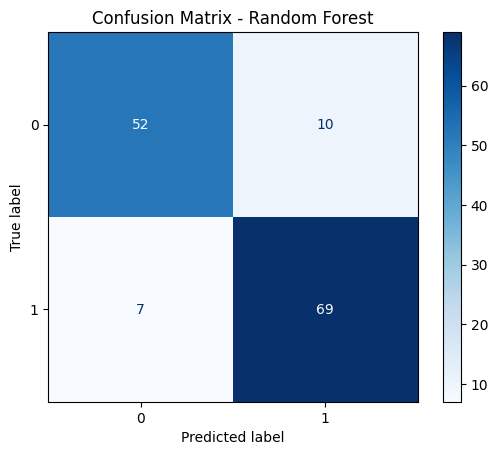


CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.88      0.84      0.86        62
           1       0.87      0.91      0.89        76

    accuracy                           0.88       138
   macro avg       0.88      0.87      0.87       138
weighted avg       0.88      0.88      0.88       138



In [ ]:
accuracy = accuracy_score(y_test, y_pred)

print("ACCURACY RANDOM FOREST")
print("Accuracy:", round(accuracy, 4))
print("Accuracy (%):", round(accuracy * 100, 2), "%")


cm = confusion_matrix(
    y_test,
    y_pred,
    labels=classification_pipeline.classes_
)

print("\nCONFUSION MATRIX")
print(cm)


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classification_pipeline.classes_
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix - Random Forest")
plt.show()


print("\nCLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)


Feature Importance:


,Feature,Importance
20,cat__ST_Slope_Up,0.157703
19,cat__ST_Slope_Flat,0.097941
3,num__MaxHR,0.094666
4,num__Oldpeak,0.091021
7,cat__ChestPainType_ASY,0.084447
2,num__Cholesterol,0.073688
0,num__Age,0.068911
1,num__RestingBP,0.068306
16,cat__ExerciseAngina_N,0.051815
17,cat__ExerciseAngina_Y,0.050810


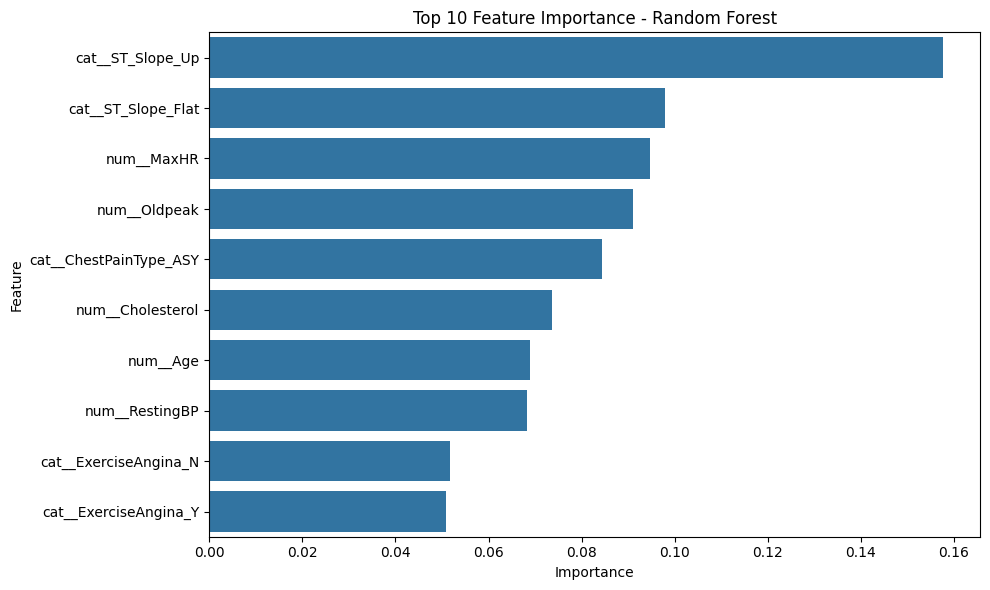

In [ ]:
trained_rf = classification_pipeline.named_steps["classifier"]

trained_feature_names = (
    classification_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

feature_importance = pd.DataFrame({
    "Feature": trained_feature_names,
    "Importance": trained_rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Feature Importance:")
display(feature_importance)


plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Feature Importance - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()


In [ ]:
kmeans_model = KMeans(
    n_clusters=3,
    n_init=20,
    max_iter=300,
    random_state=42
)

print("Model K-Means berhasil dibuat.")

print("\nParameter model:")
print(kmeans_model.get_params())


Model K-Means berhasil dibuat.

Parameter model:
{'algorithm': 'lloyd', 'copy_x': True, 'init': 'k-means++', 'max_iter': 300, 'n_clusters': 3, 'n_init': 20, 'random_state': 42, 'tol': 0.0001, 'verbose': 0}


In [ ]:
cluster_labels = kmeans_model.fit_predict(X_cluster)

print("Proses clustering selesai.")

# Menambahkan hasil cluster ke DataFrame
clustering_result = df_clean.copy()

clustering_result["Cluster"] = cluster_labels

display(clustering_result.head(10))


Proses clustering selesai.


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,Cluster
0,40,M,ATA,140.0,289.0,0,Normal,172.0,N,0.0,Up,0,2
1,49,F,NAP,160.0,NaN,0,Normal,156.0,N,1.0,Flat,1,2
2,37,M,ATA,130.0,283.0,0,ST,98.0,N,0.0,Up,0,2
3,48,F,ASY,138.0,214.0,0,Normal,108.0,Y,1.5,Flat,1,1
4,54,M,NAP,150.0,195.0,0,Normal,122.0,N,0.0,Up,0,2
5,39,M,NAP,120.0,339.0,0,Normal,170.0,N,0.0,Up,0,2
6,45,F,ATA,130.0,237.0,0,Normal,170.0,N,0.0,Up,0,2
7,54,M,ATA,110.0,208.0,0,Normal,142.0,N,0.0,Up,0,2
8,37,M,ASY,140.0,207.0,0,Normal,130.0,Y,1.5,Flat,1,1
9,48,F,ATA,120.0,284.0,0,Normal,120.0,N,0.0,Up,0,2


In [ ]:
sse = kmeans_model.inertia_

silhouette_avg = silhouette_score(
    X_cluster,
    cluster_labels
)

print("HASIL EVALUASI K-MEANS")

print("Jumlah cluster:", 3)
print("SSE:", round(sse, 4))
print("Silhouette Score:", round(silhouette_avg, 4))


HASIL EVALUASI K-MEANS
Jumlah cluster: 3
SSE: 5477.1846
Silhouette Score: 0.1256


In [ ]:
cluster_distribution = (
    pd.Series(cluster_labels, name="Cluster")
    .value_counts()
    .sort_index()
)

print("Jumlah anggota setiap cluster:")

display(cluster_distribution.to_frame("Jumlah Data"))

print("\nPersentase anggota setiap cluster:")

display(
    (cluster_distribution / len(cluster_labels) * 100)
    .round(2)
    .to_frame("Persentase (%)")
)


Jumlah anggota setiap cluster:


,Jumlah Data
Cluster,
0,247
1,288
2,383



Persentase anggota setiap cluster:


,Persentase (%)
Cluster,
0,26.91
1,31.37
2,41.72


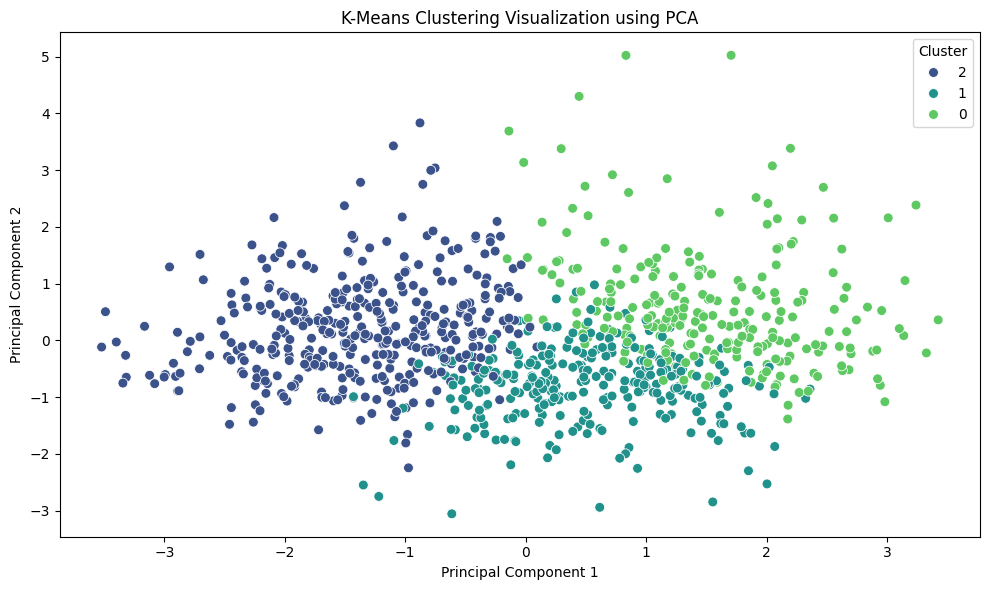

Total variance explained by 2 PCA components: 39.31 %


In [ ]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_cluster)

pca_df = pd.DataFrame(
    X_pca,
    columns=["PCA 1", "PCA 2"]
)

pca_df["Cluster"] = cluster_labels.astype(str)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=pca_df,
    x="PCA 1",
    y="PCA 2",
    hue="Cluster",
    palette="viridis",
    s=50
)

plt.title("K-Means Clustering Visualization using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")

plt.tight_layout()
plt.show()

print(
    "Total variance explained by 2 PCA components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)



In [ ]:
cluster_label_comparison = pd.crosstab(
    clustering_result["Cluster"],
    clustering_result["HeartDisease"],
    margins=True
)

print("Perbandingan Cluster dengan HeartDisease:")

display(cluster_label_comparison)


Perbandingan Cluster dengan HeartDisease:


HeartDisease,0,1,All
Cluster,,,
0,37,210,247
1,72,216,288
2,301,82,383
All,410,508,918


In [ ]:
print("=" * 60)
print("FINAL MACHINE LEARNING RESULT")
print("=" * 60)

print("\nDATASET")
print("Jumlah data:", len(df_clean))
print("Jumlah atribut prediktor:", X.shape[1])
print("Jumlah fitur setelah preprocessing:", X_cluster.shape[1])

print("\nCLASSIFICATION - RANDOM FOREST")
print("n_estimators: 400")
print("max_depth: 12")
print("min_samples_leaf: 1")
print("random_state: 42")

print("Training data:", len(X_train))
print("Testing data:", len(X_test))

print("Accuracy:", round(accuracy * 100, 2), "%")

print("\nConfusion Matrix:")
print(cm)

print("\nCLUSTERING - K-MEANS")
print("n_clusters: 3")
print("n_init: 20")
print("max_iter: 300")
print("random_state: 42")

print("SSE:", round(sse, 4))
print("Silhouette Score:", round(silhouette_avg, 4))

print("\nCluster Distribution:")
print(cluster_distribution)

print("\n" + "=" * 60)
print("PROCESS COMPLETED")
print("=" * 60)




FINAL MACHINE LEARNING RESULT

DATASET
Jumlah data: 918
Jumlah atribut prediktor: 11
Jumlah fitur setelah preprocessing: 21

CLASSIFICATION - RANDOM FOREST
n_estimators: 400
max_depth: 12
min_samples_leaf: 1
random_state: 42
Training data: 780
Testing data: 138
Accuracy: 87.68 %

Confusion Matrix:
[[52 10]
 [ 7 69]]

CLUSTERING - K-MEANS
n_clusters: 3
n_init: 20
max_iter: 300
random_state: 42
SSE: 5477.1846
Silhouette Score: 0.1256

Cluster Distribution:
Cluster
0    247
1    288
2    383
Name: count, dtype: int64

PROCESS COMPLETED
